In [5]:
!nvidia-smi
!pip install -q ultralytics roboflow

Sat Nov 21 08:32:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')
SAVE = "/content/drive/MyDrive/yolo_assignment"

Mounted at /content/drive


In [10]:
from roboflow import Roboflow
rf = Roboflow(api_key="YOUR_API_KEY") # roboflow api key
project = rf.workspace("surcrious1s-workspace").project("machine-learning-yihbi")
version = project.version(2)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 0.1%
Version export complete for yolov8 format



Extracting Dataset Version Zip to machine-learning-2 in yolov8:: 100%|██████████| 725/725 [00:00<00:00, 7094.08it/s]


In [11]:
import os, yaml
root = dataset.location
for s in ["train", "valid", "test"]:
    p = f"{root}/{s}/images"
    print(s, len(os.listdir(p)) if os.path.exists(p) else "없음")

train 252
valid 72
test 36


In [12]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
model.train(data=f"{dataset.location}/data.yaml", epochs=50, imgsz=640, batch=16,
            project=SAVE, name="train", exist_ok=True)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/machine-learning-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7dd152c3f4d0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [13]:
best = YOLO(f"{SAVE}/train/weights/best.pt")
m = best.val(data=f"{dataset.location}/data.yaml")
print(f"mAP50: {m.box.map50:.3f} | mAP50-95: {m.box.map:.3f} | P: {m.box.mp:.3f} | R: {m.box.mr:.3f}")
for i, n in best.names.items():
    print(n, f"{m.box.maps[i]:.3f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1740.2±364.1 MB/s, size: 41.1 KB)
val: Scanning /content/machine-learning-2/valid/labels.cache... 72 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 72/72 23.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.7it/s 1.9s
                   all         72         74      0.997          1      0.995      0.988
                   fan         23         23      0.997          1      0.995      0.974
                figure         28         28      0.998          1      0.995      0.995
             pepsi_can         23         23      0.996          1      0.995      0.995
Speed: 2.9ms preprocess, 6.7ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /content/runs/detect/val
mAP50: 

results.png


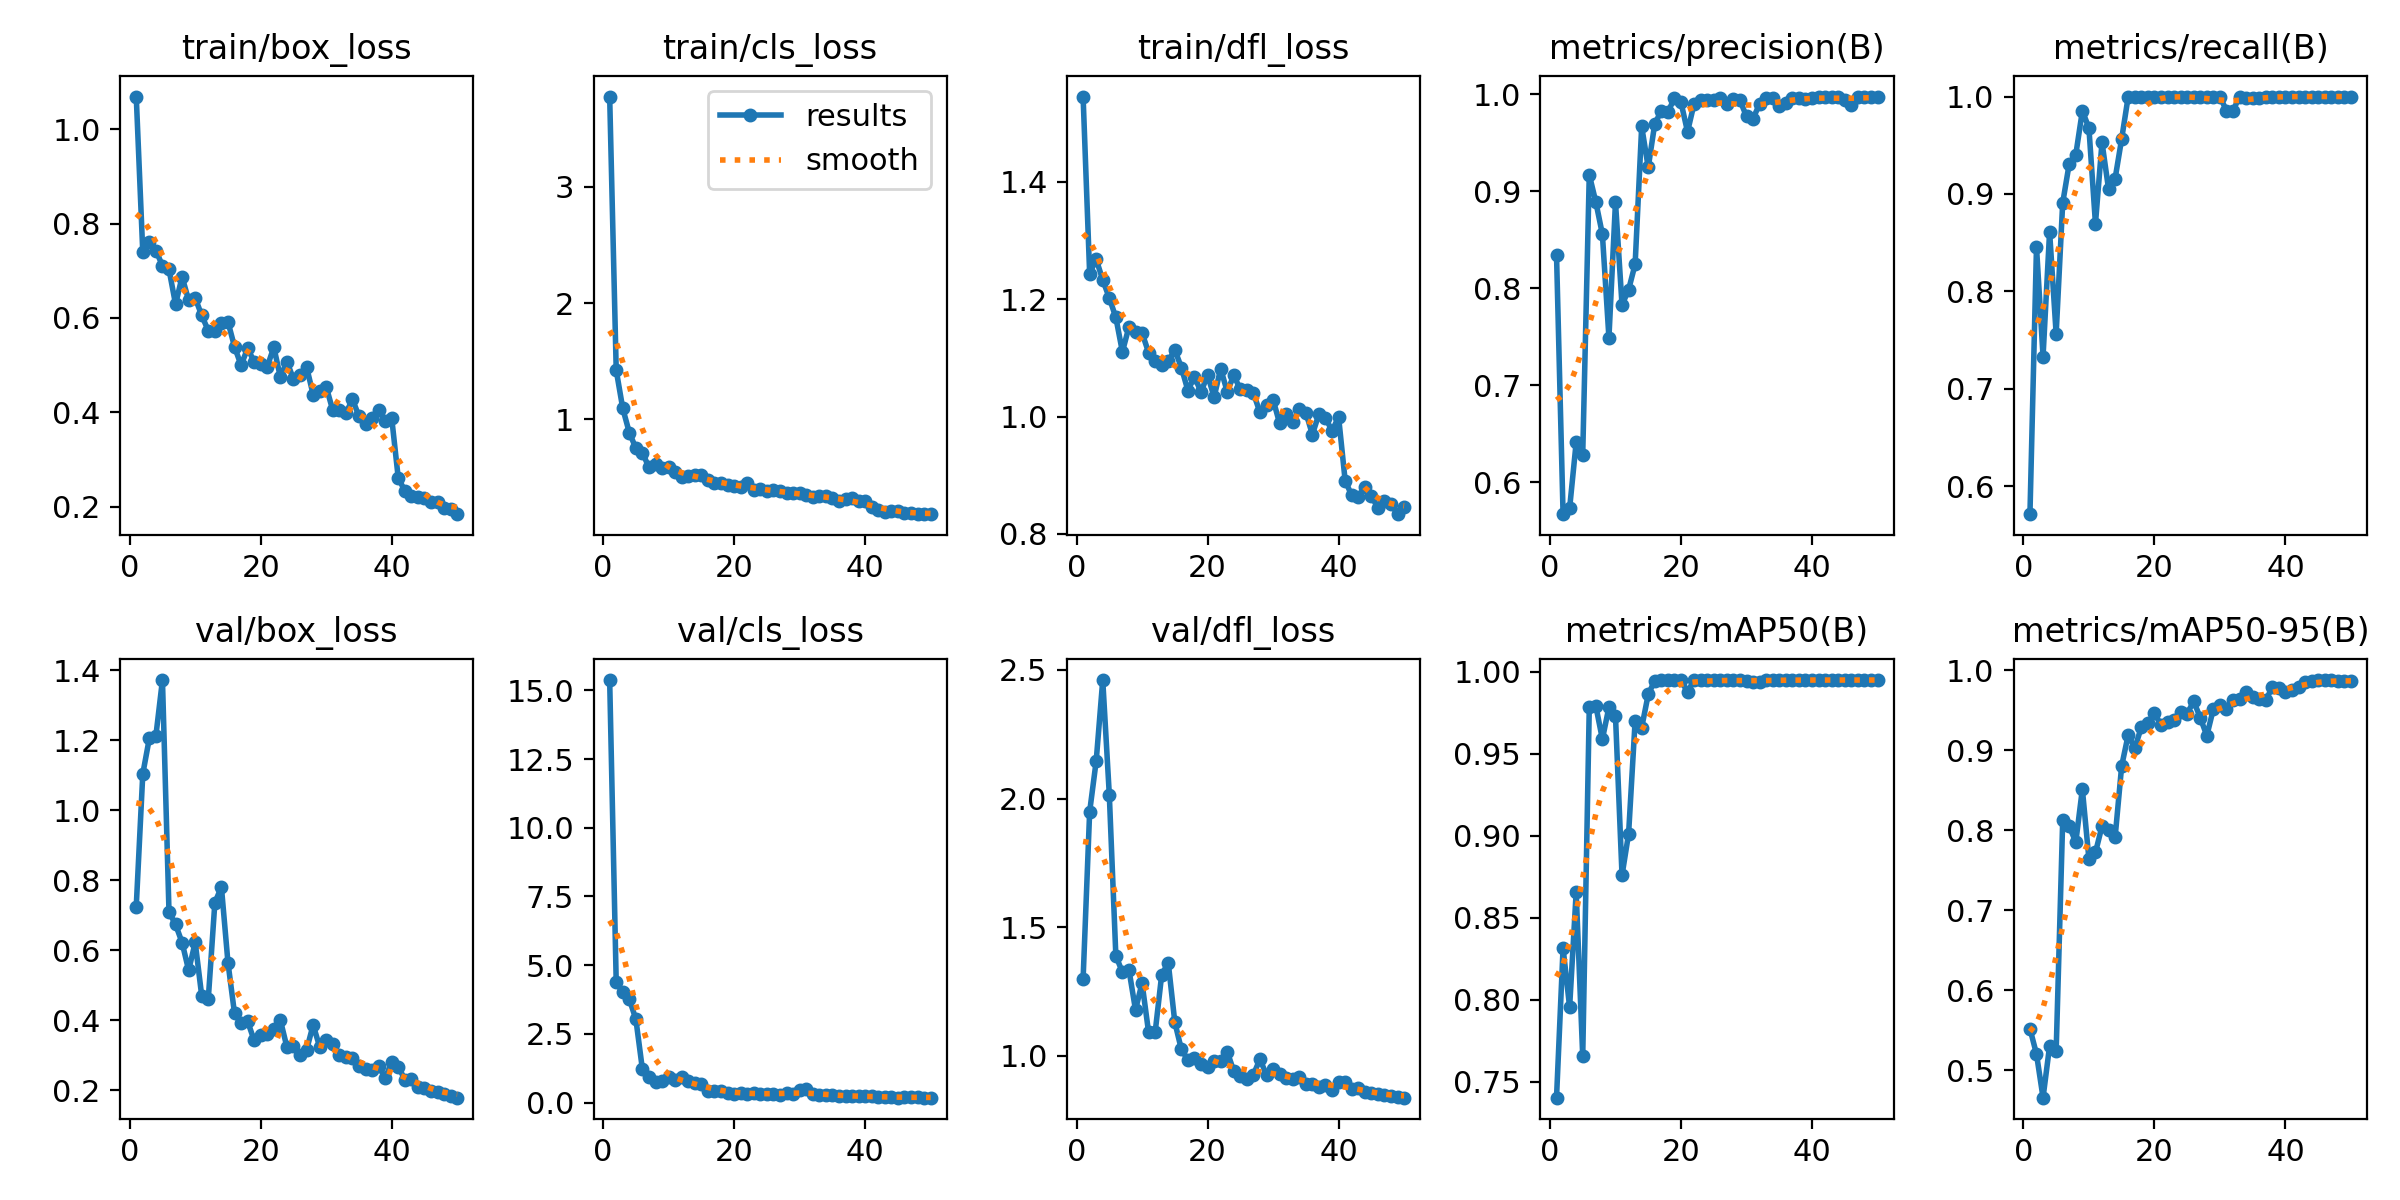

confusion_matrix.png


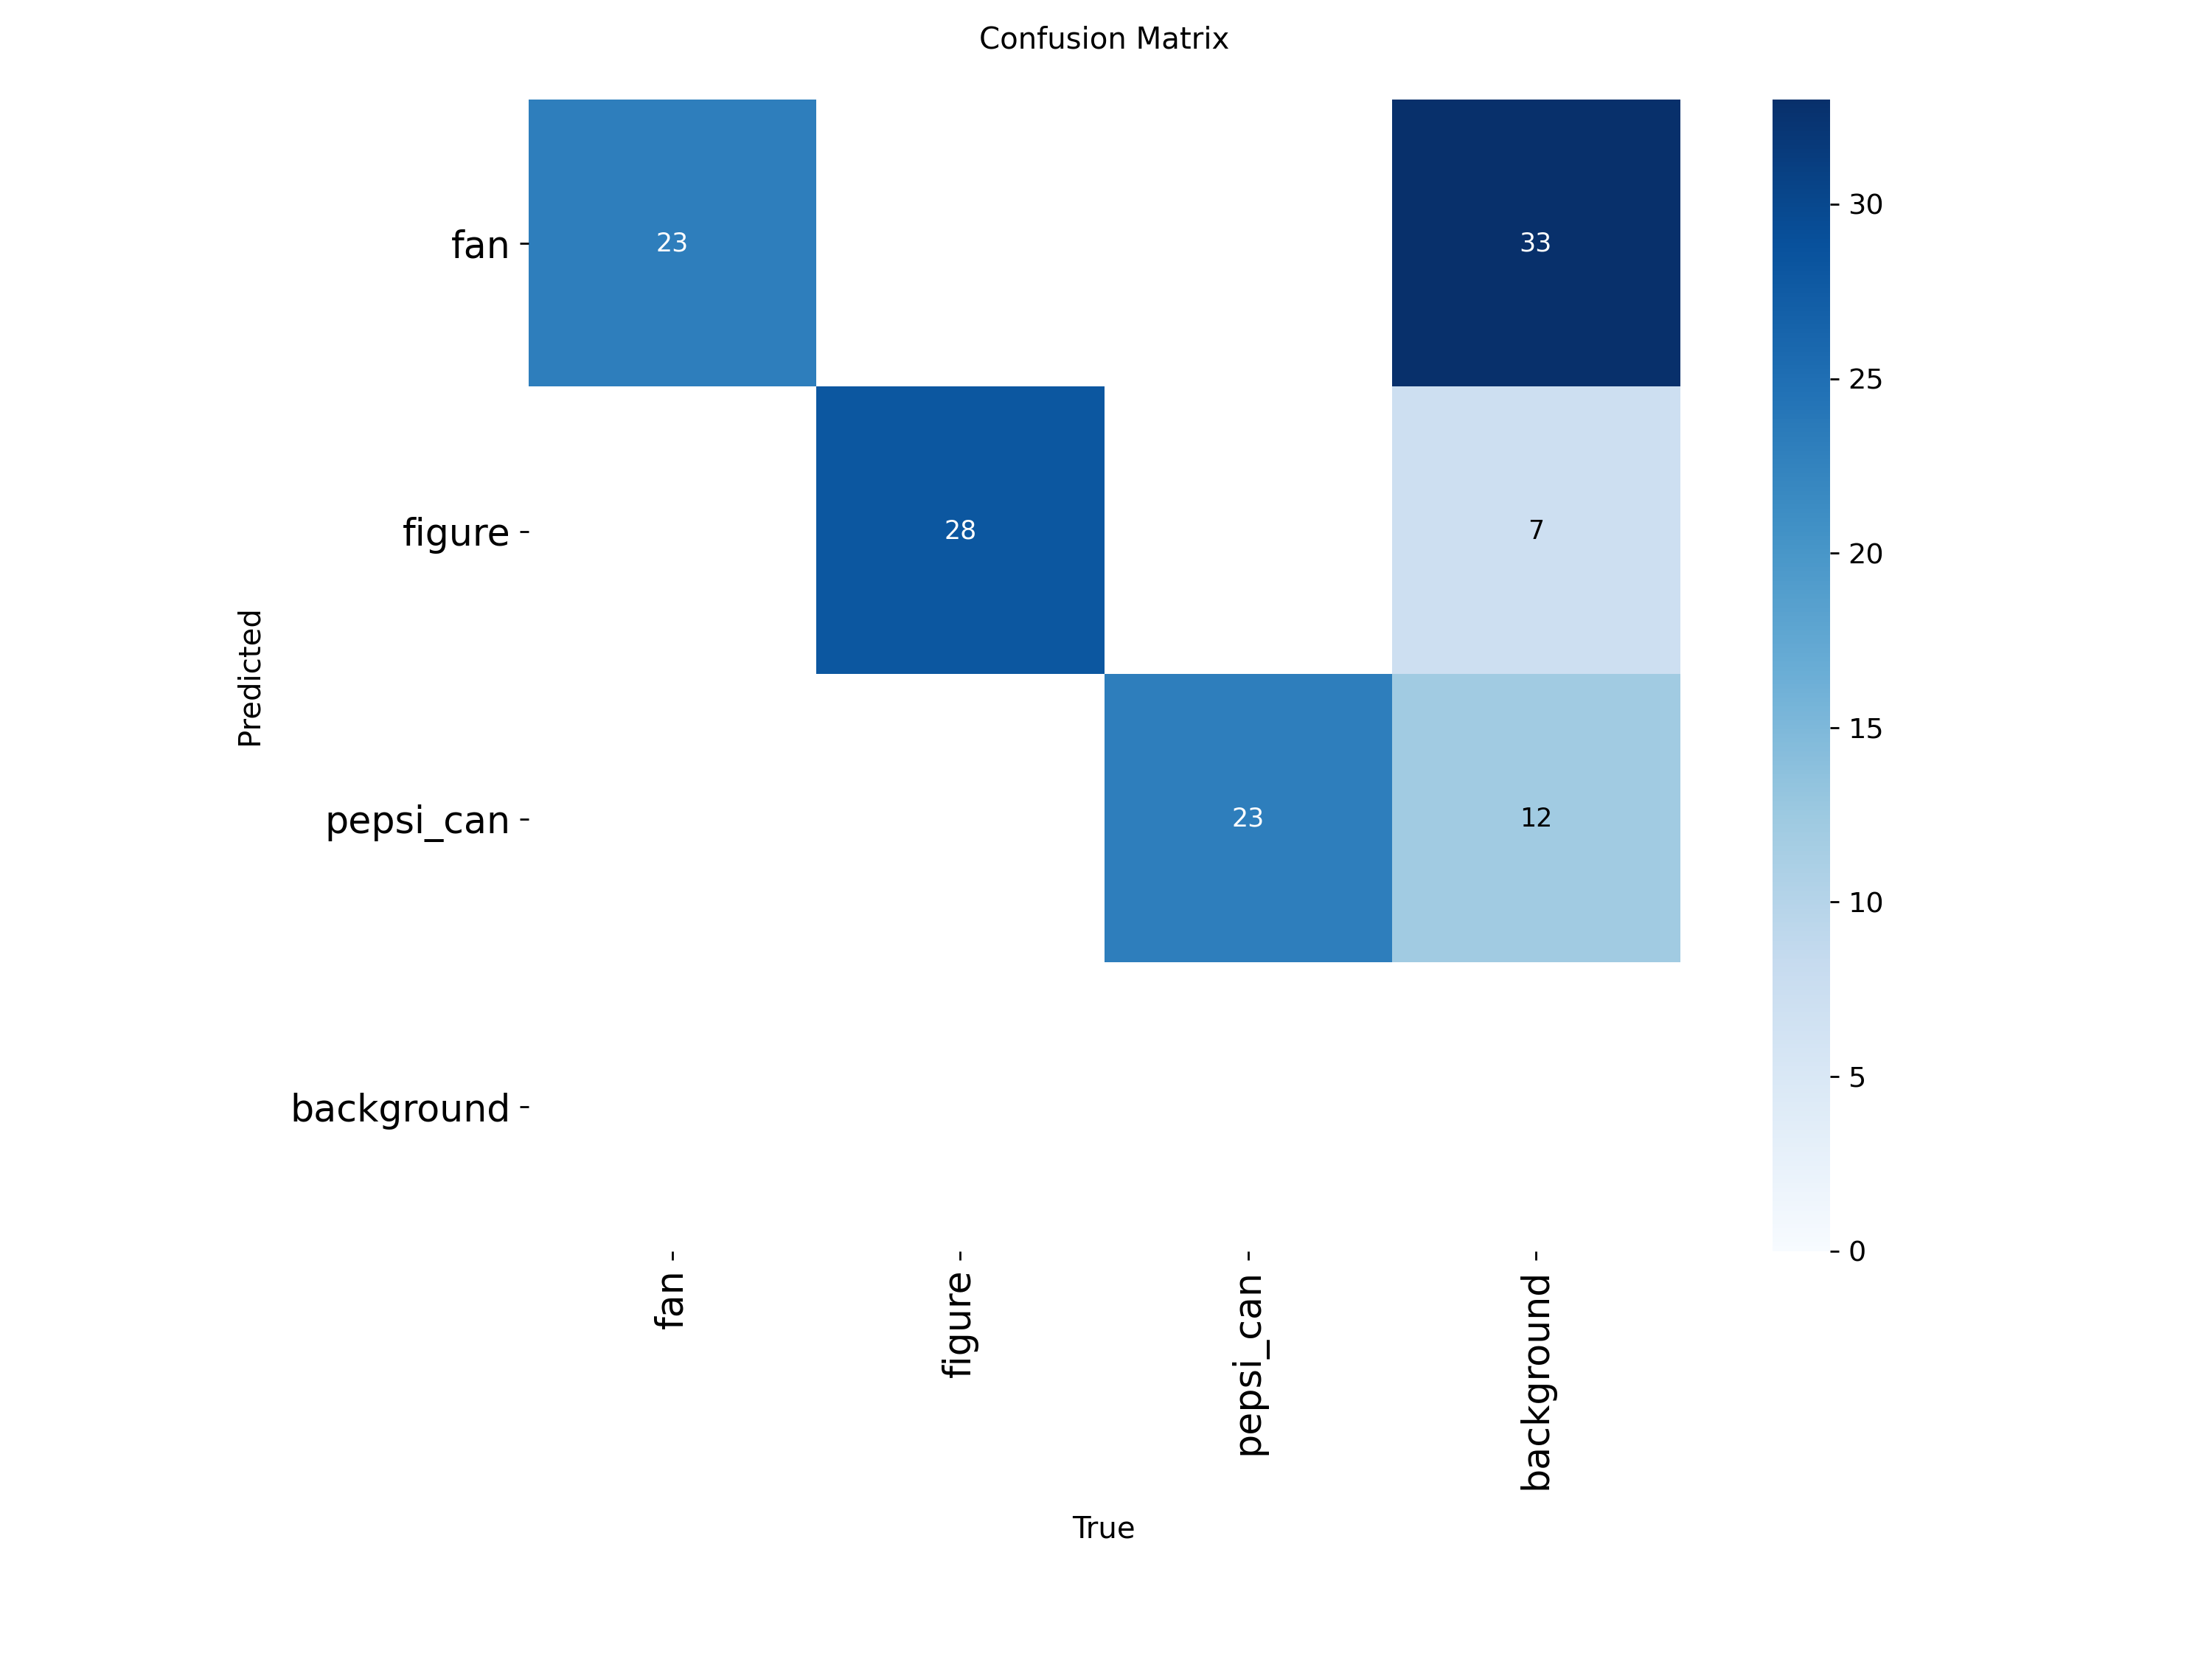

BoxPR_curve.png


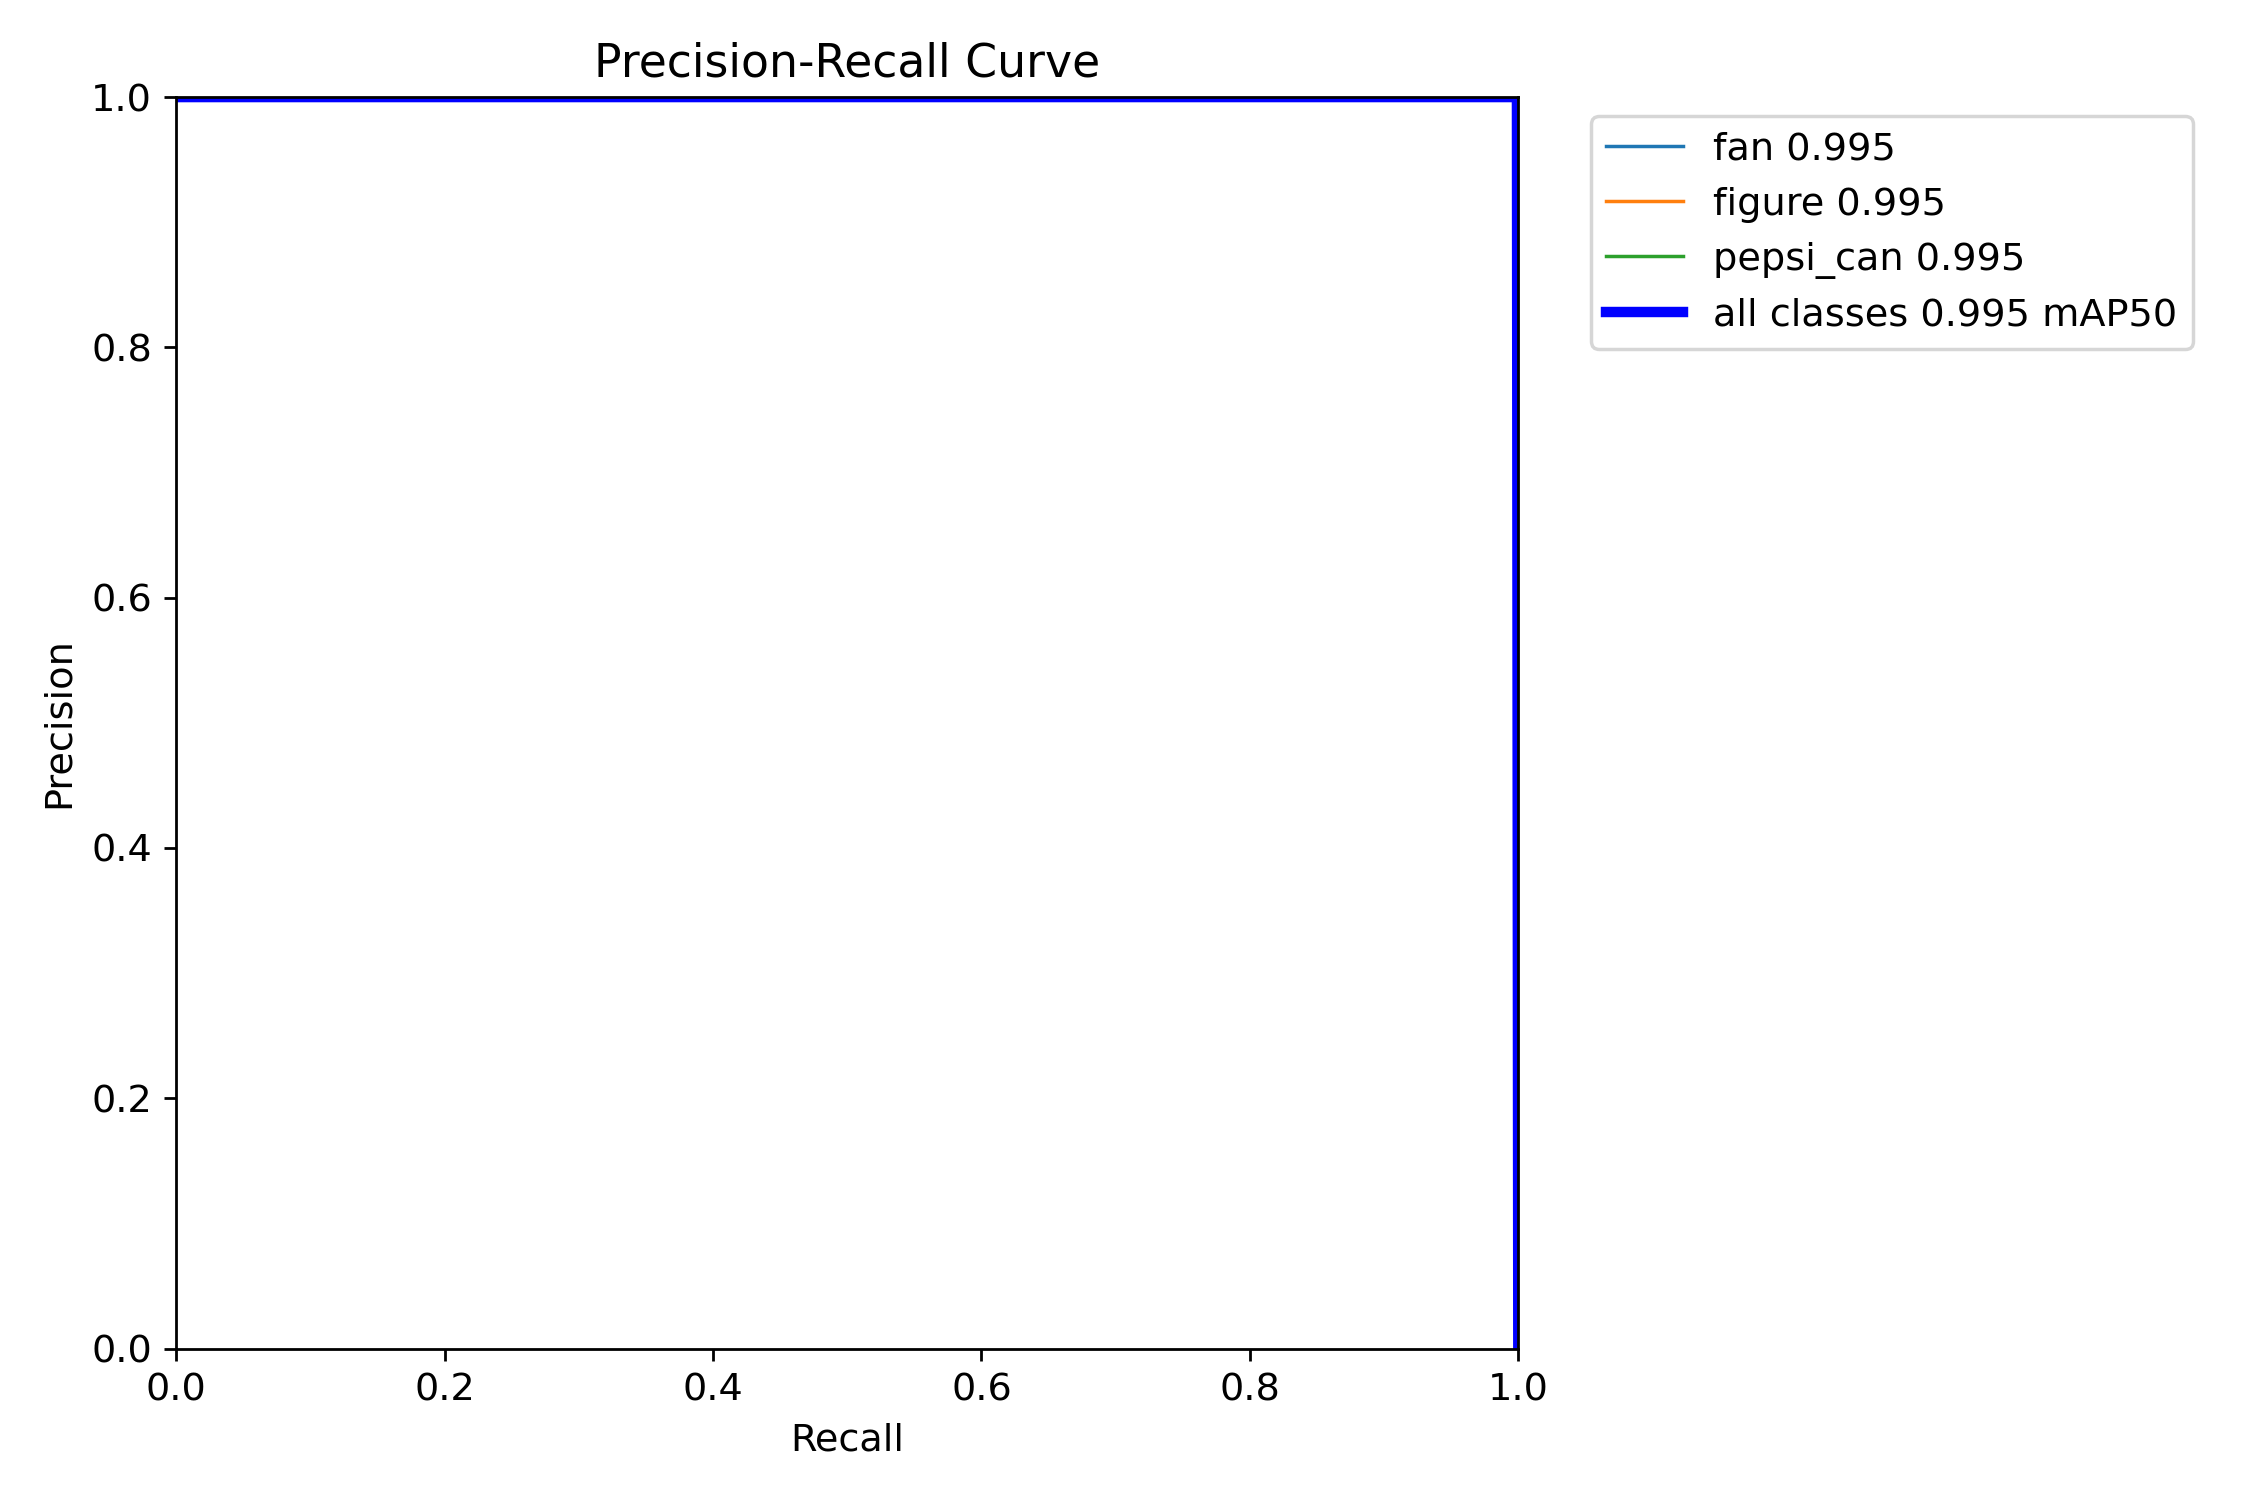

In [14]:
from IPython.display import Image, display
import os
for f in ["results.png", "confusion_matrix.png", "BoxPR_curve.png"]:
    p = f"{SAVE}/train/{f}"
    if os.path.exists(p):
        print(f); display(Image(p, width=700))
    else:
        print("없음:", f)

In [15]:
t = best.val(data=f"{dataset.location}/data.yaml", split="test")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 883.8±348.5 MB/s, size: 41.4 KB)
val: Scanning /content/machine-learning-2/test/labels... 36 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 36/36 2.1Kit/s 0.0s
val: New cache created: /content/machine-learning-2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.6it/s 1.1s
                   all         36         38      0.993          1      0.995      0.984
                   fan         14         14      0.988          1      0.995      0.963
                figure         12         12      0.993          1      0.995      0.995
             pepsi_can         12         12      0.996          1      0.995      0.995
Speed: 3.5ms preprocess, 7.6ms inference, 0.0ms loss, 1.7ms postproces

In [15]:
from google.colab import drive
drive.mount('/content/drive')
SAVE = "/content/drive/MyDrive/yolo_assignment"

from ultralytics import YOLO
best = YOLO(f"{SAVE}/train/weights/best.pt")
print("모델 클래스:", best.names)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
모델 클래스: {0: 'fan', 1: 'figure', 2: 'pepsi_can'}


In [16]:
import cv2, csv, numpy as np
from collections import defaultdict

VIDEO = "/content/drive/MyDrive/20261121_174545.mp4"
cap = cv2.VideoCapture(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS) or 30
W, H = int(cap.get(3)), int(cap.get(4))
out = cv2.VideoWriter("/content/raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))

hist, rows = defaultdict(list), []
for f in range(int(fps * 5)):
    ok, frame = cap.read()
    if not ok: break
    r = best.track(frame, persist=True, tracker="bytetrack.yaml", conf=0.4, verbose=False)[0]
    img = r.plot()
    if r.boxes.id is not None:
        for (x, y, w, h), tid, c in zip(r.boxes.xywh.cpu().numpy(), r.boxes.id.int().tolist(), r.boxes.cls.int().tolist()):
            hist[tid].append((x, y))
            rows.append([f, round(f / fps, 3), tid, best.names[c], round(float(x), 1), round(float(y), 1)])
            cv2.polylines(img, [np.array(hist[tid], np.int32).reshape(-1, 1, 2)], False, (0, 255, 255), 3)
    out.write(img)
cap.release(); out.release()

with open(f"{SAVE}/trajectory.csv", "w", newline="") as fp:
    w = csv.writer(fp); w.writerow(["frame", "time_s", "id", "class", "cx", "cy"]); w.writerows(rows)
print("처리 프레임:", f + 1, "| 추적된 ID:", list(hist.keys()))

처리 프레임: 150 | 추적된 ID: [1, 2, 6, 8]


In [17]:
!ffmpeg -y -loglevel error -i /content/raw.mp4 -vcodec libx264 -pix_fmt yuv420p "{SAVE}/tracking_result.mp4"

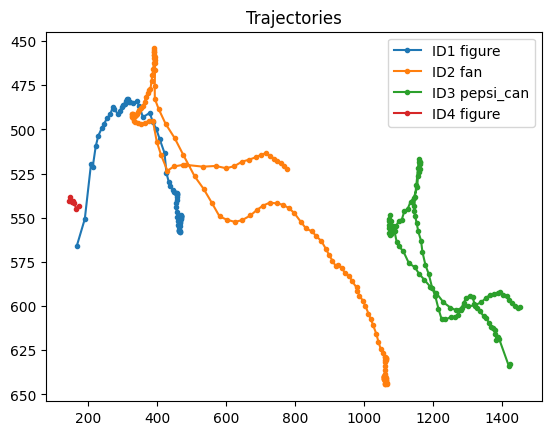

In [13]:
import pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv(f"{SAVE}/trajectory.csv")
for tid, g in df.groupby("id"):
    plt.plot(g.cx, g.cy, marker=".", label=f"ID{tid} {g['class'].iloc[0]}")
plt.gca().invert_yaxis(); plt.legend(); plt.title("Trajectories")
plt.savefig(f"{SAVE}/trajectory.png", dpi=150); plt.show()

In [18]:
!cp -r /content/runs/detect "{SAVE}/val_results"
!cp /content/*.mp4 "{SAVE}/"

cp: cannot stat '/content/runs/detect': No such file or directory
